# 04 · Série real: consumo de energia elétrica (Electricity)

Até aqui usamos uma série **sintética**, em que sabíamos a resposta (lags 1, 24, 168 e 720). Agora testamos as mesmas abordagens num **dado real e público**.

**Dataset:** *ElectricityLoadDiagrams20112014* (UCI Machine Learning Repository), na versão horária usada por Lai et al. (2018, LSTNet) e depois em Informer, Autoformer e em vários trabalhos com SSMs:
- 321 clientes de uma distribuidora portuguesa, consumo **horário**, 26.304 horas (2012 a 2014);
- usamos **um cliente** (o último, nº 320), que é o alvo padrão da versão univariada desse benchmark.

Por que esse dado: consumo de energia tem **ciclo diário (24 h)** e **ciclo semanal (168 h)**, as mesmas escalas que colocamos na série sintética. A diferença é que agora a relação não é linear e nem fixa: há feriados, estações do ano, mudanças de padrão.

Roteiro:
1. Download e leitura
2. Limpeza
3. Visualização (série completa e zooms)
4. Perfis diário e semanal
5. Autocorrelação: os lags 24 e 168 aparecem?
6. Salvar a série para os modelos

## 1. Download e leitura

In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DADOS = ROOT / "dados"
BRUTO = DADOS / "reais" / "electricity.txt.gz"
FIG_DIR = ROOT / "results" / "figuras"; FIG_DIR.mkdir(parents=True, exist_ok=True)

URL = "https://raw.githubusercontent.com/laiguokun/multivariate-time-series-data/master/electricity/electricity.txt.gz"
CLIENTE = 320           # coluna usada (0 a 320)

if not BRUTO.exists():
    BRUTO.parent.mkdir(parents=True, exist_ok=True)
    print("baixando", URL)
    urllib.request.urlretrieve(URL, BRUTO)

tabela = pd.read_csv(BRUTO, header=None)       # 26.304 linhas (horas) × 321 colunas (clientes)
print("tabela:", tabela.shape)
y_bruto = tabela[CLIENTE].to_numpy(dtype=float)
print(f"cliente {CLIENTE}: {len(y_bruto)} horas · mín {y_bruto.min():.0f} · máx {y_bruto.max():.0f} · média {y_bruto.mean():.0f}")

tabela: (26304, 321)
cliente 320: 26304 horas · mín 0 · máx 6035 · média 3336


### Estilo (mesmo tema escuro dos slides)

In [2]:
BG, FG, MUTED, GRID = "#0E1117", "#E6E8EE", "#8B93A1", "#232B38"
ACC, ORANGE = "#8FA8FF", "#F2A65A"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "axes.edgecolor": MUTED,
    "axes.labelcolor": FG, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": FG,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 15, "legend.frameon": False, "savefig.dpi": 200,
})

def salvar(fig, nome):
    caminho = FIG_DIR / f"{nome}.png"
    fig.savefig(caminho, bbox_inches="tight")
    print("figura salva em", caminho.relative_to(ROOT))

## 2. Limpeza

Valores **zero** são falhas de medição (o cliente não deixa de consumir energia por uma hora). Trocamos por interpolação linear entre os vizinhos. É uma limpeza mínima: o resto da série fica como veio.

In [3]:
y = pd.Series(y_bruto).replace(0, np.nan)
n_falhas = int(y.isna().sum())
y = y.interpolate(limit_direction="both").to_numpy()
print(f"{n_falhas} horas com zero foram interpoladas")
n = len(y)
train_end, val_end = int(0.7 * n), int(0.7 * n) + int(0.1 * n)
print(f"treino: 0–{train_end-1} | validação: {train_end}–{val_end-1} | teste: {val_end}–{n-1}  (mesmo corte 70/10/20 da série sintética)")

3 horas com zero foram interpoladas
treino: 0–18411 | validação: 18412–21041 | teste: 21042–26303  (mesmo corte 70/10/20 da série sintética)


## 3. Visualização

figura salva em results/figuras/real_serie_completa.png


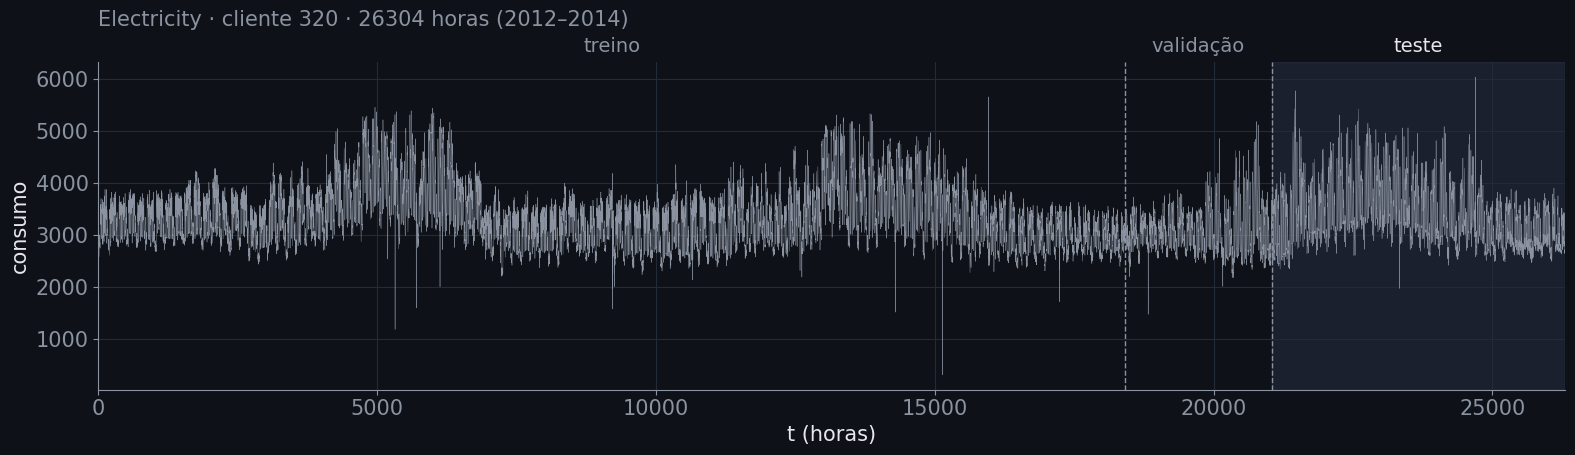

In [4]:
fig, ax = plt.subplots(figsize=(16, 4.8))
ax.plot(np.arange(n), y, color=MUTED, lw=0.3)
ax.axvspan(val_end, n, color=ACC, alpha=0.10)
for x in (train_end, val_end):
    ax.axvline(x, color=MUTED, lw=1, ls="--")
for ini, fim, nome in [(0, train_end, "treino"), (train_end, val_end, "validação"), (val_end, n, "teste")]:
    ax.text((ini + fim) / 2, 1.02, nome, transform=ax.get_xaxis_transform(), ha="center", va="bottom",
            color=FG if nome == "teste" else MUTED, fontsize=14)
ax.set(xlim=(0, n), xlabel="t (horas)", ylabel="consumo")
ax.set_title(f"Electricity · cliente {CLIENTE} · {n} horas (2012–2014)", loc="left", color=MUTED, fontsize=15, pad=26)
fig.tight_layout(); salvar(fig, "real_serie_completa"); plt.show()

figura salva em results/figuras/real_serie_zooms.png


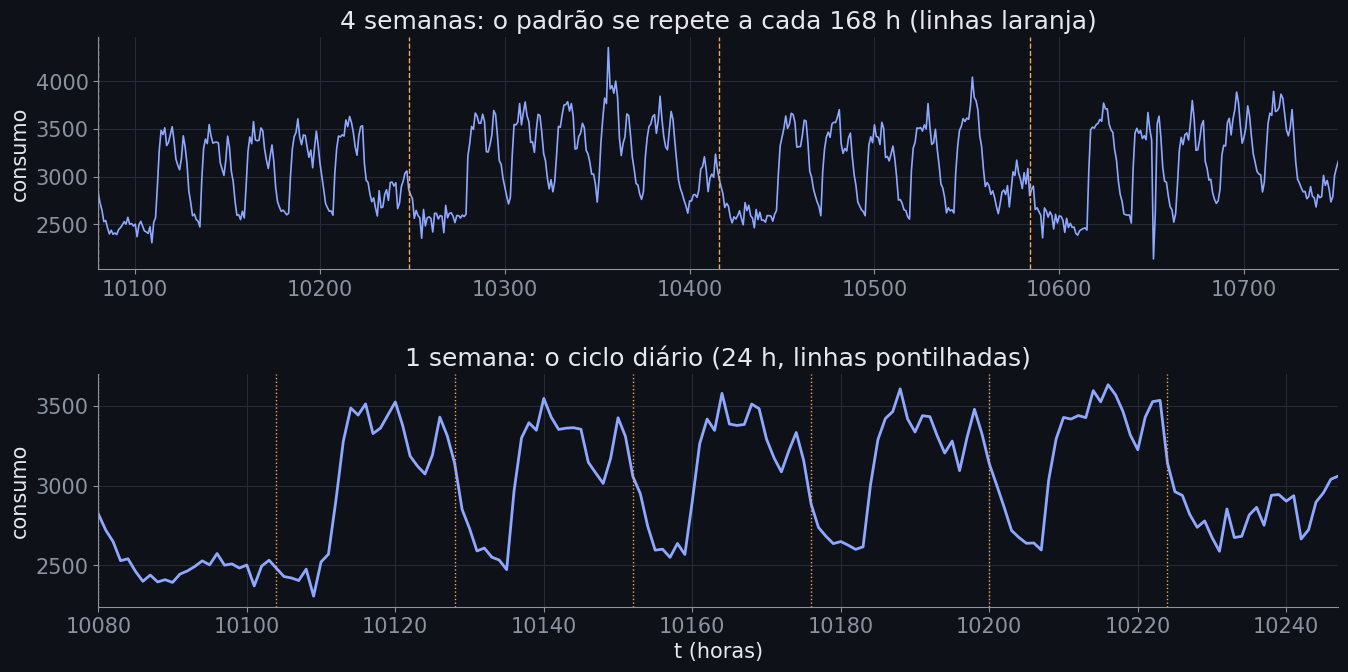

In [5]:
INICIO = 24 * 7 * 60          # começa na semana 60 (um trecho qualquer do treino)
fig, (a0, a1) = plt.subplots(2, 1, figsize=(16, 7.4), gridspec_kw={"hspace": 0.45})
t4 = np.arange(INICIO, INICIO + 24 * 7 * 4)
a0.plot(t4, y[t4], color=ACC, lw=1.2)
for k in range(5):
    a0.axvline(INICIO + 168 * k, color=ORANGE, lw=1, ls="--")
a0.set(xlim=(t4[0], t4[-1]), ylabel="consumo", title="4 semanas: o padrão se repete a cada 168 h (linhas laranja)")
t1 = np.arange(INICIO, INICIO + 168)
a1.plot(t1, y[t1], color=ACC, lw=2)
for k in range(8):
    a1.axvline(INICIO + 24 * k, color=ORANGE, lw=1, ls=":")
a1.set(xlim=(t1[0], t1[-1]), xlabel="t (horas)", ylabel="consumo", title="1 semana: o ciclo diário (24 h, linhas pontilhadas)")
salvar(fig, "real_serie_zooms"); plt.show()

## 4. Perfis diário e semanal

Média do consumo por **hora do dia** e por **hora da semana** (no treino). Se existe um ciclo, o perfil médio mostra o formato dele.

figura salva em results/figuras/real_perfis.png


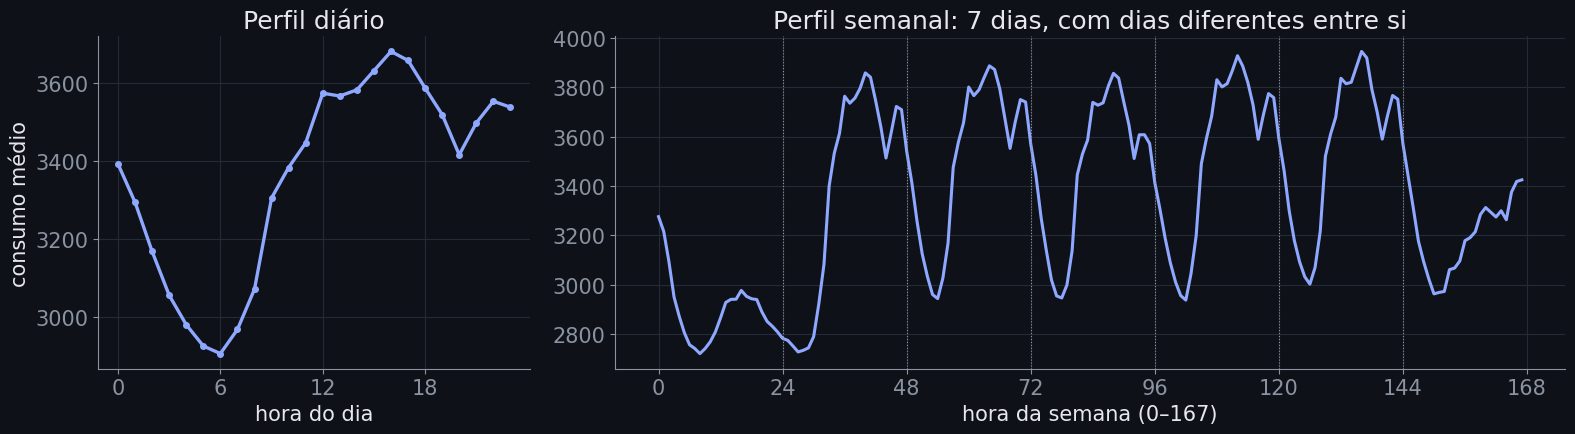

In [6]:
h = np.arange(n)
tr = h < train_end
perfil_dia = pd.Series(y[tr]).groupby(h[tr] % 24).mean()
perfil_sem = pd.Series(y[tr]).groupby(h[tr] % 168).mean()

fig, (a0, a1) = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 2.2]})
a0.plot(perfil_dia.index, perfil_dia.values, color=ACC, lw=2.4, marker="o", ms=4)
a0.set(xlabel="hora do dia", ylabel="consumo médio", title="Perfil diário", xticks=range(0, 24, 6))
a1.plot(perfil_sem.index, perfil_sem.values, color=ACC, lw=2.2)
for k in range(1, 7):
    a1.axvline(24 * k, color=MUTED, lw=0.8, ls=":")
a1.set(xlabel="hora da semana (0–167)", title="Perfil semanal: 7 dias, com dias diferentes entre si", xticks=range(0, 169, 24))
fig.tight_layout(); salvar(fig, "real_perfis"); plt.show()

## 5. Autocorrelação

A mesma ferramenta do notebook 01: correlação entre yₜ e yₜ₋ₖ, para k até 800. Picos em 24, 168 (e múltiplos) indicam as dependências que um bom modelo precisa capturar.

figura salva em results/figuras/real_acf.png


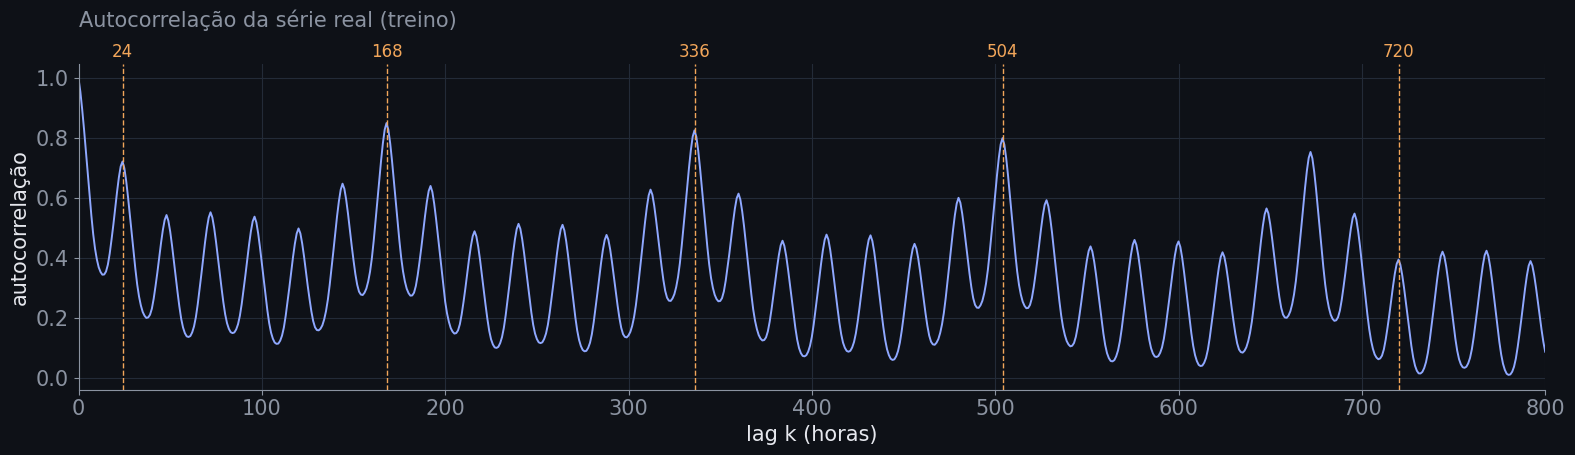

lag    1: autocorrelação = 0.955
lag   24: autocorrelação = 0.723
lag  168: autocorrelação = 0.851
lag  720: autocorrelação = 0.395


In [7]:
def acf(x, max_lag):
    x = (x - x.mean()) / x.std()
    return np.array([1.0] + [np.mean(x[k:] * x[:-k]) for k in range(1, max_lag + 1)])

r = acf(y[:train_end], 800)
fig, ax = plt.subplots(figsize=(16, 4.8))
ax.plot(np.arange(len(r)), r, color=ACC, lw=1.4)
for lag in (24, 168, 336, 504, 720):
    ax.axvline(lag, color=ORANGE, lw=1, ls="--")
    ax.text(lag, 1.02, str(lag), transform=ax.get_xaxis_transform(), ha="center", color=ORANGE, fontsize=12)
ax.set(xlabel="lag k (horas)", ylabel="autocorrelação", xlim=(0, 800))
ax.set_title("Autocorrelação da série real (treino)", loc="left", color=MUTED, fontsize=15, pad=26)
fig.tight_layout(); salvar(fig, "real_acf"); plt.show()
for lag in (1, 24, 168, 720):
    print(f"lag {lag:4d}: autocorrelação = {r[lag]:.3f}")

**Como ler:** os picos em 24 e, mais forte, em 168 (e 336, 504…) confirmam os dois ciclos. Diferente da série sintética, aqui ninguém escolheu os lags: eles vêm do comportamento real de consumo. E a relação não é fixa: feriados, verão/inverno e mudanças de rotina alteram o padrão.

## 6. Salvar a série para os modelos

Mesmo formato da série sintética (`dados/serie_sintetica.csv`): uma coluna `y`. Os configs `exp_real_*.json` apontam para este arquivo.

In [8]:
saida = DADOS / "electricity_mt320.csv"
pd.DataFrame({"t": np.arange(n), "y": y}).to_csv(saida, index=False)
print("salvo em", saida.relative_to(ROOT), "·", n, "pontos")

salvo em dados/electricity_mt320.csv · 26304 pontos
